# Data Workflow

In the [previous section](5_Rotation_Profiles_Workflow.ipynb) we ran the nineteen *GAMESS* jobs of the torsion scan and collected the last `NSERCH` line of each log file into the file `data/butane_result.txt`. If you open that file in a text editor you will see nineteen lines of data, one line for each file.

Within the file name is the torsion angle. The step number for the last energy calculation, NSERCH, is next. The energy follows that and the value is in units of hartree/molecule. We will want to convert that to kJ/mol. Then we have the energy gradient for the last structure of the optimization. It should be less than 0.0001 for the calculation to stop. We could have set this lower or higher. The last value recorded in each line is the RMS deviation for the gradient calculation.

```{note}
The file `data/butane_result.txt` comes with the book, so you can work through this notebook without running the scan first. If you run the [workflow notebook](5_Rotation_Profiles_Workflow.ipynb) yourself, it overwrites this file with your own results.
```

In [1]:
from pathlib import Path

DATA = Path("data")     # butane_result.txt and the plot style sheet live here
RUNS = Path("runs")     # files we write go here
RUNS.mkdir(exist_ok=True)

print((DATA / "butane_result.txt").read_text())

butane_SCAN_000.log:  NSERCH:  22  E=     -156.4228465105  GRAD. MAX=  0.0000535  R.M.S.=  0.0000171
butane_SCAN_010.log:  NSERCH:  18  E=     -156.4233726954  GRAD. MAX=  0.0000801  R.M.S.=  0.0000247
butane_SCAN_020.log:  NSERCH:  16  E=     -156.4247889427  GRAD. MAX=  0.0000743  R.M.S.=  0.0000226
butane_SCAN_030.log:  NSERCH:  16  E=     -156.4267021324  GRAD. MAX=  0.0000576  R.M.S.=  0.0000202
butane_SCAN_040.log:  NSERCH:  19  E=     -156.4286427109  GRAD. MAX=  0.0000494  R.M.S.=  0.0000153
butane_SCAN_050.log:  NSERCH:  30  E=     -156.4301846915  GRAD. MAX=  0.0000774  R.M.S.=  0.0000194
butane_SCAN_060.log:  NSERCH:  22  E=     -156.4310610865  GRAD. MAX=  0.0000787  R.M.S.=  0.0000309
butane_SCAN_070.log:  NSERCH:  29  E=     -156.4312168554  GRAD. MAX=  0.0000616  R.M.S.=  0.0000227
butane_SCAN_080.log:  NSERCH:  29  E=     -156.4306888896  GRAD. MAX=  0.0000614  R.M.S.=  0.0000249
butane_SCAN_090.log:  NSERCH:  27  E=     -156.4295738742  GRAD. MAX=  0.0000884  R.M.S.=  

Observe the `NSERCH` column: most jobs converged in fewer than 30 steps, but a few took a **longer time** to converge. We could open them in *MacMolPlt* and watch a "movie" of their journey and plot the energies along the way. Where did they get stuck? They all eventually found their way home, but only because this was a light-weight theory level and I was confident in allowing for a large number of steps. If the level of theory was higher I might have set the limit to 100 steps, or even 30 steps.

Why did these take so long? Bad luck with the exact structure of the input started them on the long path. Tweak a few bond lengths or angles and they might converge just like the others. Clearly, how you start matters. For high levels of theory it is important to start as close to the final answer as possible.

## Import Raw Data

We could edit the data in a text editor but we will do everything using the data analysis tools of *Python* and *pandas*. First we will import the data as a dataframe using *pandas*. The data file must be in the folder we give, so we build the path with `DATA / "butane_result.txt"`. Don't worry, *Python* will scream at you if you make a mistake and you will be able to fix any problems.

We will use the `pandas.read_csv()` function to read the file and create a dataframe object. The `header = None` setting prevents the first line from being used to label the columns. The `sep` setting says what separates one column from the next. Each line looks like this:

```text
butane_SCAN_000.log:  NSERCH:  23  E=     -156.4228465418  GRAD. MAX=  0.0000585  R.M.S.=  0.0000204
```

`sep = r"\.log:\s+|\s+|_"` is a *regular expression* with three choices separated by `|`: the text `.log:` followed by spaces, one or more spaces (`\s+`), or the `_` character. That cuts the file name `butane_SCAN_000.log:` into `butane`, `SCAN` and `000`, so the torsion angle gets a column of its own. The `engine = "python"` means to use the *Python* engine rather than the default *C* engine. The *C* engine is much faster, but it is not compatible with the way I am using the `sep` parameter. How do I know this? I got an error message that told me what to do.

In [2]:
import pandas as pd

df = pd.read_csv(DATA / "butane_result.txt", header = None, sep = r"\.log:\s+|\s+|_", engine = "python")
display(df.head())

,0,1,2,3,4,5,6,7,8,9,10,11
0,butane,SCAN,0,NSERCH:,22,E=,-156.422847,GRAD.,MAX=,0.000053,R.M.S.=,0.000017
1,butane,SCAN,10,NSERCH:,18,E=,-156.423373,GRAD.,MAX=,0.000080,R.M.S.=,0.000025
2,butane,SCAN,20,NSERCH:,16,E=,-156.424789,GRAD.,MAX=,0.000074,R.M.S.=,0.000023
3,butane,SCAN,30,NSERCH:,16,E=,-156.426702,GRAD.,MAX=,0.000058,R.M.S.=,0.000020
4,butane,SCAN,40,NSERCH:,19,E=,-156.428643,GRAD.,MAX=,0.000049,R.M.S.=,0.000015


## Cleaning the Data

Data cleaning is half the work in data analysis. We need to drop empty records and malformed records (each line could be considered a record in this case). We will need to drop any fields we don't need (the columns in each record are the fields). Inspecting the dataframe shows me that I only need columns 2, 4, 6 and 9. We will rename the columns for what they represent. Inspect the original dataframe above to see where I got my labels from.

In the code below I create a new dataframe by selecting the four chosen columns out of the previous dataframe. Then I renamed the column headers from numbers to labels so I don't forget what they are.

In [3]:
butane = df[[2, 4, 6, 9]]
butane = butane.rename({2:'Torsion', 4:'NSERCH', 6:'Energy', 9:'GRAD'}, axis='columns')
display(butane.head())

,Torsion,NSERCH,Energy,GRAD
0,0,22,-156.422847,0.000053
1,10,18,-156.423373,0.000080
2,20,16,-156.424789,0.000074
3,30,16,-156.426702,0.000058
4,40,19,-156.428643,0.000049


## Processing the Data

We now have a cleaned up data set. We could have done all of this in *Excel* by importing the text file, setting column breaks manually, deleting unwanted columns manually and then typing in names for the columns. *Python* and *pandas* may seem like a bit of work but it is not any more than you would do setting up the data in *Excel*.

We know that a hartree is $2625.5\, \mathrm{kJ/mol}$. So we can convert the energy to a more familiar unit. Then we should set our lowest energy structure as the zero reference and subtract that value from all the energies to establish a relative scale.

In [4]:
import numpy as np
hartree_conversion = 2625.5      # kJ/mol per hartree

lowest_energy = np.min(butane["Energy"])
butane["DeltaE"] = (butane["Energy"] - lowest_energy) * hartree_conversion
display(butane)

,Torsion,NSERCH,Energy,GRAD,DeltaE
0,0,22,-156.422847,0.000053,25.257817
1,10,18,-156.423373,0.000080,23.876318
2,20,16,-156.424789,0.000074,20.157961
3,30,16,-156.426702,0.000058,15.134881
4,40,19,-156.428643,0.000049,10.039893
5,50,30,-156.430185,0.000077,5.991423
6,60,22,-156.431061,0.000079,3.690447
7,70,29,-156.431217,0.000062,3.281476
8,80,29,-156.430689,0.000061,4.667650
9,90,27,-156.429574,0.000088,7.595123


## Plotting the Profile

Now we have a set of data that we can plot. Let us visualize the profile using the *Matplotlib* library.

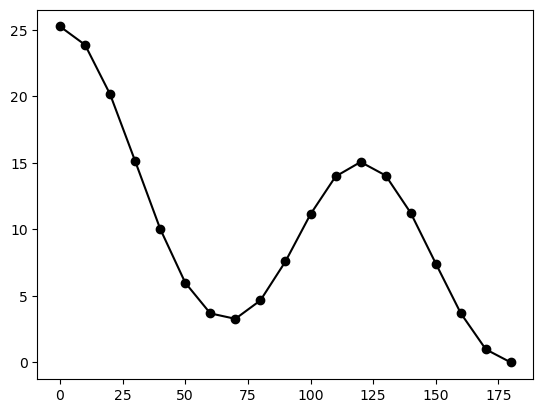

In [5]:
import matplotlib.pyplot as plt

x = butane["Torsion"]
y = butane["DeltaE"]

plt.plot(x, y, "ko-")
plt.show()

## Publication Quality

We can be more stylish. I will use the style sheet that I edited to my preference. It is the file `S2_classic2.mplstyle` in the `data` folder.

Different journals have different standards for plots. Just follow their instructions. Many will have style sheets available for your word processor, for $\LaTeX$ and even for *MacMolPlt*. Use the `savefig()` method of the `fig` object to save the plot as a file. The `.pdf` extension will tell it to save in PDF format.

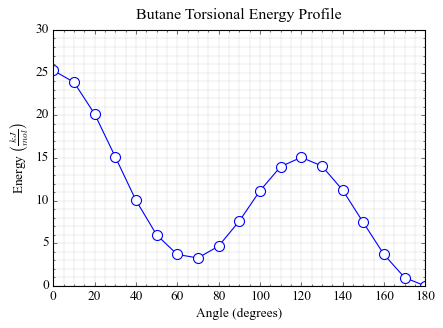

In [6]:
x = butane["Torsion"]
y = butane["DeltaE"]

plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))

ax.plot(x, y, "o-")

ax.set(title="Butane Torsional Energy Profile",
          ylabel=r"Energy $\left(\frac{kJ}{mol}\right)$",
          xlabel="Angle (degrees)",
          xlim=[0,180],
          ylim=[0,30]
      )

#fig.savefig(RUNS / "plot.pdf")
plt.show()

The plot above is a "connect-the-dots" style plot. There are many data points and it looks fine. We do not have an exact function to which to fit the data but we could apply the infamous "cubic spline." We will use the `CubicSpline` function available from the `scipy.interpolate` library ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)) to generate a function that represents the curve fit. We will then feed an x-axis of many data points into that function to create an x,y data set that represents that curve fit as a smooth line.

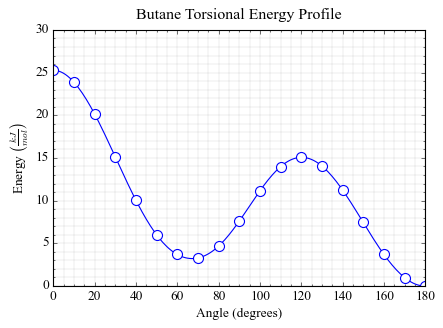

In [7]:
from scipy.interpolate import CubicSpline

plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))

cs = CubicSpline(x, y)
x_smooth = np.arange(0, 181, 1)
ax.plot(x_smooth, cs(x_smooth), "-")

ax.plot(x, y, "o")

ax.set(title="Butane Torsional Energy Profile",
          ylabel=r"Energy $\left(\frac{kJ}{mol}\right)$",
          xlabel="Angle (degrees)",
          xlim=[0,180],
          ylim=[0,30]
      )

#fig.savefig(RUNS / "plot.pdf")
plt.show()

The spline is also a function we can ask questions of. Where is the *gauche* minimum? We can search the smooth curve for the lowest point between 30&deg; and 120&deg;, and for the top of the barrier between 90&deg; and 150&deg;.

In [8]:
x_fine = np.arange(0, 180.01, 0.1)
y_fine = cs(x_fine)

gauche = (x_fine > 30) & (x_fine < 100)
barrier = (x_fine > 90) & (x_fine < 150)
i = np.argmin(np.where(gauche, y_fine, np.inf))
j = np.argmax(np.where(barrier, y_fine, -np.inf))
print(f"gauche minimum: {x_fine[i]:5.1f} degrees, {y_fine[i]:5.2f} kJ/mol above anti")
print(f"eclipsed max:   {x_fine[j]:5.1f} degrees, {y_fine[j]:5.2f} kJ/mol above anti")

gauche minimum:  67.2 degrees,  3.21 kJ/mol above anti
eclipsed max:   120.2 degrees, 15.07 kJ/mol above anti


The spline puts the *gauche* minimum close to the 67&deg; we found by optimizing without a frozen torsion, and it shows that the eclipsed maximum is not exactly at 120&deg;. Remember that a spline only joins the dots smoothly: with points every 10&deg; these positions are estimates, not new calculations.

## Saving the Data

We have imported, cleaned and processed the data. Maybe we should save our work so we can use this data set directly and easily next time. The dataframe object contains methods to do this. We will use the `pandas.DataFrame.to_csv()` method ([documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html)) to save the dataframe object as a csv text file.

In [9]:
butane.to_csv(RUNS / "butane_profile.csv")

The butane energy profile data is now saved in a file named `runs/butane_profile.csv`. Below, the file is read back and printed so you can see the csv format.

In [10]:
print((RUNS / "butane_profile.csv").read_text())

,Torsion,NSERCH,Energy,GRAD,DeltaE
0,0,22,-156.4228465105,5.35e-05,25.25781672154649
1,10,18,-156.4233726954,8.01e-05,23.876318266605807
2,20,16,-156.4247889427,7.43e-05,20.15796098045608
3,30,16,-156.4267021324,5.76e-05,15.134881423055404
4,40,19,-156.4286427109,4.94e-05,10.039892571349242
5,50,30,-156.4301846915,7.74e-05,5.9914225060612125
6,60,22,-156.4310610865,7.87e-05,3.6904474335456854
7,70,29,-156.4312168554,6.16e-05,3.2814761865559916
8,80,29,-156.4306888896,6.14e-05,4.667650394502417
9,90,27,-156.4295738742,8.84e-05,7.595123327174221
10,100,30,-156.4282209524,7.42e-05,11.147219513052406
11,110,27,-156.427141473,7.89e-05,13.981392677765157
12,120,564,-156.4267262798,9.85e-05,15.071482424398525
13,130,25,-156.4271135021,4.34e-05,14.054830275695792
14,140,25,-156.428185206,8.98e-05,11.241071686294475
15,150,23,-156.4296328253,7.8e-05,7.440347214157498
16,160,23,-156.4310598487,7.9e-05,3.693697277462732
17,170,23,-156.4320918062,9.96e-05,0.9842928612023485
18,180,32,-156.43246670

## AI Statement

This notebook was already a *Jupyter* notebook in the original book (`5_Rotation_Profiles_Workflow_Data.ipynb`). It was adapted with the help of Claude (Anthropic), following the author's instructions.

- **Original text and code kept (about 85 %).** The explanations of importing, cleaning, processing, plotting, spline fitting and saving the data, and the code that does it, are the author's. Typos were fixed.
- **Changed.** The data and the style sheet are read from the book's `data/` folder instead of a GitHub URL, and `butane_result.txt` is now written by the [workflow notebook](5_Rotation_Profiles_Workflow.ipynb). Because the file names no longer carry the *GamessQ* job number, the `sep` pattern and the column numbers changed. The hartree conversion is now 2625.5 kJ/mol (the original used 2625.7). The copy of the result file and the csv file are printed by code instead of being pasted into the text.
- **Written by AI.** The note about where the data comes from, the explanation of the new `sep` pattern, and the short section that uses the spline to estimate the *gauche* minimum and the eclipsed maximum.